# 📘 9.2 Stiff Ordinary Differential Equations
###

This notebook examines what happens when an ODE has components that evolve at different rates, that may take the form of rapidly varying transients and slow changing modes. For a stability perspective, the explicity solutions we have introduced in Notebooks [7.2](https://colab.research.google.com/drive/1fGC3AhR4GCxkD0tnTFpre3Av38sCPOLZ?usp=playground
) and [7.3](https://colab.research.google.com/drive/191bRXMsLSQNT-E1j4BgNzV_6aVum6CeV?usp=playground) such equations can require very short time steps and require many, many steps to evolve slower modes.

This Notebook explain how to detect these challenges, building on stability methods introduced in Notebook [9.1](https://colab.research.google.com/drive/1EEWyEXA6aLItM85ZsPW-bFMd3YheHBNw?usp=playground) and extending these to **stiff** linear and non-linear ODEs, using both Euler and RK methods.

---

### 🎯 Learning Objectives
> By the end of this notebook, you should be able to:
>
> * Understand how multiple scales can exist in an ODE and the impact this has on the step sizes associated with explicit methods.
> * Recognise that stability is set by the short time scale feature, even though this feature may decay rapidly and have neglible result on the overall solution.
> * Should be able to formulate the equations required for each step of a Euler or RK4 based solution of an ODE.
> * Be able to evaluate stability of Euler and RK4 solutions - with additional guidance as to when to use higher order expansions to simply the mathematics - example of this will be given in Workshop and Practical classes.


## 📂 9.2.0 How to use this notebook

This notebook provides computational examples of Stiff ODEs and mathematically explains how this impacts the required time step and why these become computationally expensive to solve.

> ### 🧭 Theory preface
> You are not expected to memorise the derivations, but you should be able to go from an ODE to the equations you would need to solve at each step of sub-step of an Euler or Runge-Kutta solution.
> These look complex, but are very procedural. You complete the same process each time for any given ODE.
>Concentrate on understanding the procedures and how the solutions behave.
> You should be able to use this approach to evaluate other methods of similar complexity - with guidance such as when to neglect higher order terms.

## 📂 9.2.1 Impact of Multiple Scales in an ODE

---

So far, we have focused most of our attention on ODEs in terms of the relative simple example
$$ \frac{\mbox{d}y}{\mbox{d}t} = -\lambda y$$
the analytical solution to which we can easily calculate via a separation of variables, which results in the exponential function,
$$ y(t) = y_0e^{-\lambda t},$$
where $y_0 = y(t=0)$.

This example ODE has *one* rate of decay and *one* time-scale.

---
What happens when the problem has multiple scales?

---

Consider the ODE,

$$\frac{\mbox{d}y}{\mbox{d}t}=-1000y+3000-2000e^{-t},$$

which has the analytical solution,
$$y(t) = 3-0.998e^{-1000t}-2.002 e^{-t},$$

as plotted below.


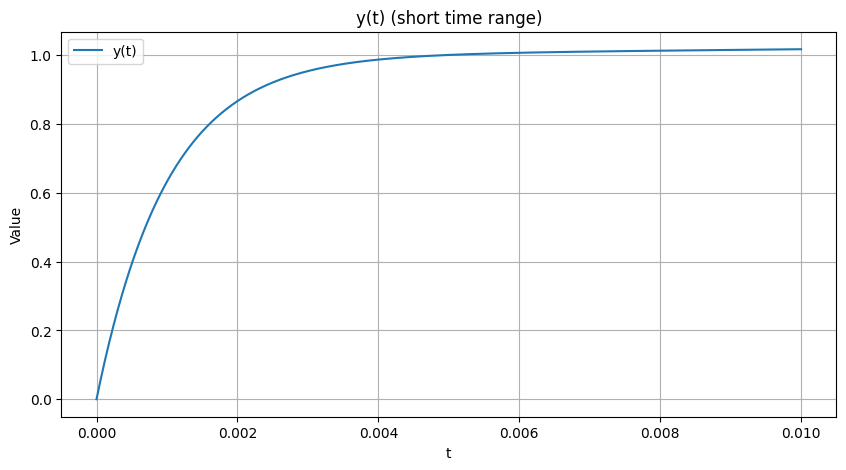

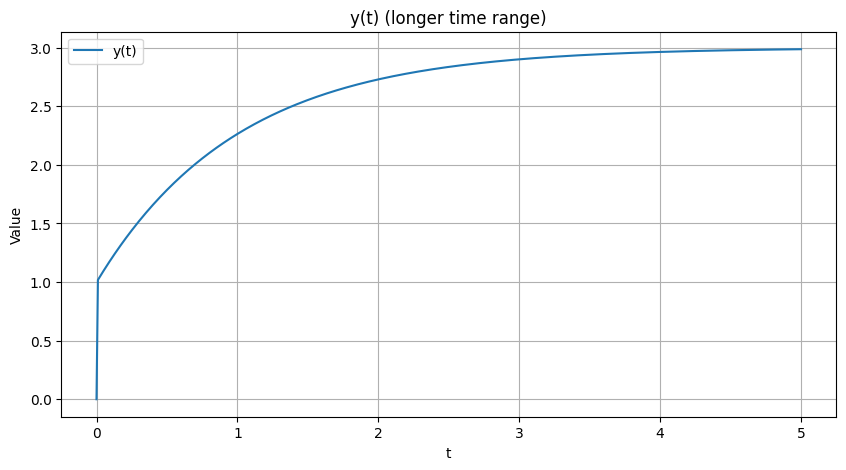

In [ ]:
# @title Short and Long Time Scale of the Analytical Solution
import numpy as np
import matplotlib.pyplot as plt

# Define the analytical solution for y(t)
def y(t):
    return 3 - 0.998 * np.exp(-1000 * t) - 2.002 * np.exp(-t)

# Create a time array
t = np.linspace(0, 0.01, 500) # Plotting a short range to see the initial fast decay
t_long = np.linspace(0, 5, 500) # Plotting a longer range to see the slow decay

# Calculate y(t) for both time ranges
y_values_short = y(t)
y_values_long = y(t_long)

# Plotting for the short time range
plt.figure(figsize=(10, 5))
plt.plot(t, y_values_short, label='y(t)')
plt.xlabel('t')
plt.ylabel('Value')
plt.title('y(t) (short time range)')
plt.legend()
plt.grid(True)
plt.show()

# Plotting for the longer time range
plt.figure(figsize=(10, 5))
plt.plot(t_long, y_values_long, label='y(t)')
plt.xlabel('t')
plt.ylabel('Value')
plt.title('y(t) (longer time range)')
plt.legend()
plt.grid(True)
plt.show()

As you can see from the plot of the longer time range, this function has a very short time-scale initial transient that decays after $t\approx 0.005$, as visible from the short time range plot. The longer scale, associated with $e^{-t}$, continues to evolve until $t\approx 5$, which is 1000 times slower than the transient.  

> ### 📖 Definition
> **Stiff Ordinary Differential Equation:** is one whose solution contains widely differing scales, where stability constraints force the numerical step size to be far smaller than what accuracy alone would require.

### 🔹 Practical Engineering Examples with Multiple Time Scales

Such diffences in scale are common in cases of
* *Compressible flow at low mach numbers* - where the flow may change slowly, but a very small timestep is required to capture the propagation of pressure waves through the fluid.
    * This is why at low mach numbers we use *incompressible codes* which avoid this problem.
* *Chemically Reacting Systems* - where different reaction have rates that vary in orders of magnitude



### 🔹 Behaviour of Euler's Method in the case of a Stiff ODE

Consider the application of the explicit Euler's Method to this stiff ODE,

$$\frac{\mbox{d}y}{\mbox{d}t}=-1000y+3000-2000e^{-t},$$

> ### ⚠️ Point of note
> By now you should be able to get from this to the numerical form of the solution of the ODE by Euler's Method. We will go through it again here.

From a Taylor series expansion

$$y_{n+1} = y_n+y'_n h + \epsilon_t$$

hence if we sub in $dy/dt$ from the ODE we get,
$$y_{n+1} = y_n+1000\left(-y_n+3-2e^{-t_n} \right)h + \epsilon_t,$$

where $h = t_{n+1}-t_n$, and

$$ t_{n} = t_0+n\cdot h.$$

In the previous example we were able to come up with an simple expression for $y_n$ in terms of the initial value $y_0$. Here we can only solve this by calculation $y$ at each time step, i.e. use $y_0$ to get $y_1$, and use that to get $y_2$, etc.

Numerically this can be evaluated as per the code below.



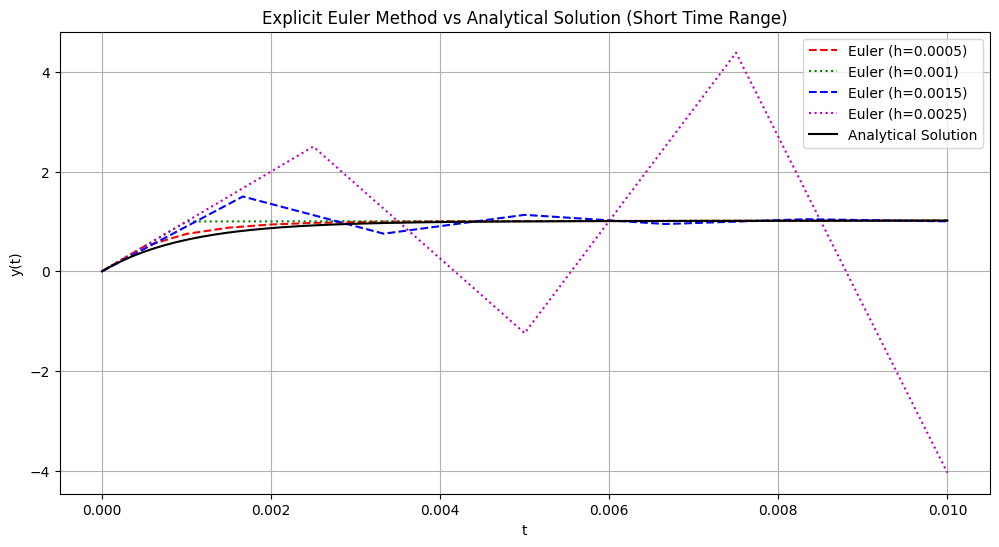

In [ ]:
# @title Effects of step size on a Stiff ODE
import numpy as np
import matplotlib.pyplot as plt

# Define the ODE function dy/dt = f(t, y)
def f(t, y):
    return -1000 * y + 3000 - 2000 * np.exp(-t)

# Define the analytical solution for comparison
def y_analytical(t):
    return 3 - 0.998 * np.exp(-1000 * t) - 2.002 * np.exp(-t)

# Initial conditions
y0 = 0.0
t0 = 0.0

# --- Simulation for a short time range (0 to 0.01) ---
t_end_short = 0.01

# Case 1:
h1 = 0.0005
# calculate steps needed to get to 0.01 seconds
num_steps1 = int((t_end_short - t0) / h1)
# pre-calculate time values
t_values1 = np.linspace(t0, t_end_short, num_steps1 + 1)
# initialise array to store y values of solution
y_euler1 = np.zeros(num_steps1 + 1)
y_euler1[0] = y0

# solver for y
for i in range(num_steps1):
    y_euler1[i+1] = y_euler1[i] + h1 * f(t_values1[i], y_euler1[i])

# Case 2:
h2 = 0.001
num_steps2 = int((t_end_short - t0) / h2)
t_values2 = np.linspace(t0, t_end_short, num_steps2 + 1)
y_euler2 = np.zeros(num_steps2 + 1)
y_euler2[0] = y0

for i in range(num_steps2):
    y_euler2[i+1] = y_euler2[i] + h2 * f(t_values2[i], y_euler2[i])

# Case 3:
h3 = 0.0015
num_steps3 = int((t_end_short - t0) / h3)
t_values3 = np.linspace(t0, t_end_short, num_steps3 + 1)
y_euler3 = np.zeros(num_steps3 + 1)
y_euler3[0] = y0

for i in range(num_steps3):
    y_euler3[i+1] = y_euler3[i] + h3 * f(t_values3[i], y_euler3[i])

# Case 4:
h4 = 0.0025
num_steps4 = int((t_end_short - t0) / h4)
t_values4 = np.linspace(t0, t_end_short, num_steps4 + 1)
y_euler4 = np.zeros(num_steps4 + 1)
y_euler4[0] = y0

for i in range(num_steps4):
    y_euler4[i+1] = y_euler4[i] + h4 * f(t_values4[i], y_euler4[i])

# Plotting for short time range
plt.figure(figsize=(12, 6))
plt.plot(t_values1, y_euler1, 'r--', label=f'Euler (h={h1})')
plt.plot(t_values2, y_euler2, 'g:', label=f'Euler (h={h2})')
plt.plot(t_values3, y_euler3, 'b--', label=f'Euler (h={h3})')
plt.plot(t_values4, y_euler4, 'm:', label=f'Euler (h={h4})')

t_analytical_short = np.linspace(t0, t_end_short, 500)
plt.plot(t_analytical_short, y_analytical(t_analytical_short), 'k-', label='Analytical Solution')

plt.xlabel('t')
plt.ylabel('y(t)')
plt.title('Explicit Euler Method vs Analytical Solution (Short Time Range)')
plt.legend()
plt.grid(True)
plt.show()

In this case we see that for step sizes $h \le 0.015$, the calculation varies from the true solution, with $h = 0.001$ and $h= 0.0015$ providing solution that fails to resolve the rapid short time-scale variable part of the solution, yet ultimately both return a stable long term solution.

The short time-scale, rapidly varying part of the solution is negligible when compared to the solution for large $t$, but it is still meaningful when it comes to the stability.

### 🔹 Stability of our Stiff ODE

Consider this stiff ODE and how it varies from our previous example. Our **stiff** ODE is of the form

$$\frac{\mbox{d}y}{\mbox{d}t}=-Ky-Ae^{-t}+B,\tag{9.8}$$

compared to the previous example
$$\frac{\mbox{d}y}{\mbox{d}t}=-Ky.\tag{9.9}$$

Recall, in the previous case we saw that the ODE in Equation 9.9 was stable for $0<hK<2$.

In the previous example, $K = 1000$, which if we neglect the other terms in Equation 9.8, corresponds to a stable step size

$$ h < 2/1000 < 0.002$$

**Note** that in the plots above we saw that the Explicity Euler Method was stable for $h = 0.0015$ and unstable for $h = 0.0025$ - consistent with the stability margin of the $-Ky$ term.

Recall, the analytical solution for an ODE of the form in Equation 9.9 is $y(t) = y_0e^{-\lambda t}$, or in this case $y(t) = y_0e^{-1000t}$, hence the overall stability of the method is limited by the stability of the short time-scale transient.

> ### ⚠️ Point of note
> This is the challenge of the **Stiff ODE**, i.e. the stability and required step size $h$, depends on short time scale, but calculations  length depends on the long time scale.
>
> In this case $h< 0.0025$ but the large scale mode evolves until $\Delta t = 5$, requiring $n = \Delta t/h = 5/0.0025 = 2000$ timesteps.    

---
Do the other terms in the ODE have no impact on the stability?

---

When applying the Taylor series expansion,

$$y_{n+1} = y_n+y'_n h + \epsilon_t,$$

to Equation 9.8, the equation to evolve $y$ becomes,

$$y_{n+1} = y_n+\left(-Ky_n-Ae^{-t}+B\right)h.\tag{9.10}$$

The terms, $Ae^{-t}+B$ involves $A$ and $B$, which are constants, hence the only term that could be perturbed would be $t$, by a machine precision rounding error.  

Consider what happends is we have a perturbated $\tilde{y}_n = y_n+\delta_y$ and a perturbed time $\tilde{t} = t+\delta_t$. Subsituting these into our expression above,

\begin{align}
\tilde{y}_{n+1} &= (1-Kh)\tilde{y}_n+\left(-Ae^{-\tilde{t}}+B\right)h\\
y_{n+1}+\delta_{y_{n+1}} &= (1-Kh)\left(y_n+\delta_{y_n}\right)+\left(-Ae^{-(t+\delta_t)}+B\right)h\\
y_{n+1}+\delta_{y_{n+1}} &= (1-Kh)\left(y_n+\delta_{y_n}\right)+\left(-Ae^{-t}e^{-\delta_t}+B\right)h
\end{align}

Consider a Taylor Series expansion of $e^{-\delta t}$ about zero,
\begin{align}e^x &= 1+x+\frac{x^2}{2!} +...\\
e^{-\delta_t} &=1-\delta_t +\frac{\delta^2_t}{2!}
\end{align}

> ### ⚠️ Point of note
> We would not expect you to come up with the Taylor series expansion of $e^{-\delta_t}$ unprompted, but you should be able to undertake the procedure up to and beyond this point.

Given $\delta_t$ is already a small perturbation, $\delta^2_t << \delta_t$ hence we can use the approximation, $e^{-\delta_t} \approx 1-\delta_t$,
such that

\begin{align}
y_{n+1}+\delta_{y_{n+1}} &= (1-Kh)\left(y_n+\delta_{y_n}\right)+\left(-Ae^{-t}(1-\delta_t)+B\right)h
\end{align}

Subtracting Equation 9.10 from above leaves the following expression for the change in the perturbation.
$$\delta_{y_{n+1}} = (1-Kh)\delta_{y_n}+A\delta_t e^{-t}h$$

The first term, $(1-Kh)\delta_{y_n}$, is the same as we had when solving $\mbox{d}y/\mbox{d}t = -Ky$, and it is this terms that tells use that the perturbation will grow from step $n$ to $n+1$ when $|1-Kh| > 1$ - our same stability condition from before.

The second term will impact the perturbation in $y$ for all values of $h$. However, this will decay in all cases as $e^{-t}→0$ as $t→0$.

Hence, the stability is still controlled by the term $Kh$.

> ### ⚠️ Point of note
> * The Explicit Euler Method is stable for $-2 < h\frac{\partial f}{\partial y} < 0$ when $\frac{\mbox{d}y}{\mbox{d}t} = f(y,t)$.
> * The problem with the STIFF ODE is that the stability time step is set by the fast transient - requires a very short time step for transient and 1000s more steps to solve longer time scale behaviour.




### 🧪 The Flame Propagation Equation - and Stability of the RK4 Solution

The model of flame propagation, credited to Larry Shampine, one of the authors of the MATLAB ODE suite, provides another example of a Stiff ODE. The model represents the growth of a spherical flame that occurs when you light a match. The ball of flame grows rapidly until it reaches a critical size. Then it remains at that size because the amount of oxygen being consumed by the combustion in the interior of the ball balances the amount available through the surface. The simple model is given by

$$ \frac{\mbox{d}y}{\mbox{d}t} = y^2 - y^3, $$
 $y(0)$ is the initial, non-zero diameter of the flame. In this case the smaller $y(0)$, the stiffer the problem.

 Consider the solution via Classical RK4 with the four sub-steps:

$$
\begin{aligned}
k_1 &= hf(t_n,y_n),\\
k_2 &= hf\!\left(t_n+\frac{h}{2},y_n+\frac{h}{2}k_1\right),\\
k_3 &= hf\!\left(t_n+\frac{h}{2},y_n+\frac{h}{2}k_2\right),\\
k_4 &= hf(t_n+h,y_n+h k_3),
\end{aligned}
$$

where $f(t,y) = \frac{\mbox{d}y}{\mbox{d}t}$. **Note**, in notebook [7.3](https://colab.research.google.com/drive/191bRXMsLSQNT-E1j4BgNzV_6aVum6CeV?usp=playground) we computed $k_1, k_2$ as rates, moving $h$ to the update step. You will find both representation used in different text, so pay close attension.

The corresponding update for the above step is

$$
\boxed{
y_{n+1}=y_n+
\frac{1}{6}(k_1+2k_2+2k_3+k_4)+\mathcal{O}(h^5)
}
$$

You should be able to manually implement this process and walk through one or two time steps. We may ask you to do this as a way of showing you understand the general working principles. We essential use the same process to assess stability.

#### Sub-Step 1

---
Consider the impact of a perturbation on such that $\tilde{y}_n = y_n+\delta_{y_n}$, through each sub-step, dropping the $t_n$ etc. as $f$ is not a function of $t$ in this case.

\begin{align}
k_1+\delta_{k_1} &= hf(t_n,y_n+\delta_{y_n})\\
k_1+\delta_{k_1} &= h\left((y_n+\delta_{y_n})^2-(y_n+\delta_{y_n})^3\right)\\
k_1+\delta_{k_1} &= h\left(y^2_n+2y_n\delta_{y_n}+\delta^2_{y_n}-(y^3_n + 3y^2_n\delta_{y_n}+3y\delta^2_{y_n}+\delta^3_{y_n})\right)
\end{align}

Now, as we are interested in the growth of perturbations, which are inherently small, we can neglect any terms $\delta^2$ or high, when to first order

$$k_1+\delta_{k_1} \approx h\left(y^2_n-y^3_n+2y_n\delta_{y_n}-3y^2_n\delta_{y_n}\right)$$
where in the absence of any perturbation
$$k_1 = h(y^2_n-y^3_n).$$
Subtracting this yield and the following expression for the uncertainty in step-1,

$$\delta_{k_1} \approx h\left(2y_n-3y^2_n\right)\delta_{y_n}\tag{9.11}$$

#### Sub-Step 2

---
The unperturbed sub-step 2 calculation is
\begin{align}
k_2 &= hf\left(y_n+\frac{h}{2}k_1\right)\\
k_2 &= h\left[\left(y_n+\frac{h}{2}k_1 \right)^2-\left(y_n+\frac{h}{2}k_1 \right)^3\right]
\end{align}

or if we let $z_2=y_n+\frac{h}{2}k_1$,

$$k_2 = h\left(z_2^2-z_2^3\right)\tag{9.12}$$

Consider the perturbed $z$

\begin{align}
\tilde{z}_2 &= z_2+\delta_z = y_n+\delta_{y_n}+\frac{h}{2}(k_1+\delta_{k_1})\\
\tilde{z}_2 &= z_2 + \delta_{y_n}+\frac{h}{2}\delta_{k_1}
\end{align}

Substituting this into Equation 9.11 we can express the equation for the perturbed step-2 as

\begin{align}
\tilde{k}_2 &= k+\delta_{k_2} = h\left(\tilde{z}^2_2-\tilde{z}^3_2\right)\\
\tilde{k}_2 &=h\left(\tilde{z}^2_2-\tilde{z}^3_2\right)\\
\tilde{k}_2 &=h\left[(z_2 + \delta_{y_n}+\frac{h}{2}\delta_{k_1})^2 - (z_2 + \delta_{y_n}+\frac{h}{2}\delta_{k_1})^3 \right]
\end{align}

> **🛑 STOP**
>
> If we manually expand this and cancel powers of $\delta$, as we did for Step-1, this gets messy - really MESSY - Let's do it a better way!

An alternative way to get to the same resolute is to approximate $\tilde{z}^2_2 - \tilde{z}^3_2$ and remove higher order terms. We can do this by replacing $f(z+\delta_z)$ with a first order Taylor Series expansion, e.g. $f(z+\delta_z)\approx f(z) +\delta_zf'(z)$. Doing this $\tilde{k_2}$ can be approximated as

\begin{align}
\tilde{k}_2 &\approx hf(z_2) + \delta_{z_2}f'(z_2)\\
\tilde{k}_2 &\approx hf(z_2) + \left(\delta_{y_n}+\frac{h}{2}\delta_{k_1}\right)f'(z_2)\\
\tilde{k}_2 &\approx h(z^2_2-z^3_2)+h(2z_2-3z^2_2)\left(\delta_{y_n}+\frac{h}{2}\delta_{k_1}\right)
\end{align}

Subtracting the unperturbed $k_2$ the expression for the perturbation on $k_2$ is approximately,

$$\delta_{k_2} \approx h(2z_2-3z^2_2)\left(\delta_{y_n}+\frac{h}{2}\delta_{k_1}\right)\tag{9.13}$$

#### Sub-Step 3

---
The unperturbed sub-step 3 calculation is
$$k_3 = hf\left(y_n+\frac{h}{2}k_2\right)$$

or if we let $z_3=y_n+\frac{h}{2}k_2$,

$$k_3 = h\left(z_3^2-z_3^3\right)$$

Step 3 follow the same trend at step 2, resulting in a similar expression for the pertubation on step 3, i.e.

$$\delta_{k_3} \approx h(2z_3-3z^2_3)\left(\delta_{y_n}+\frac{h}{2}\delta_{k_2}\right)\tag{9.14}$$

#### Sub-Step 4

---
The unperturbed sub-step 4 calculation is
$$ k_4 = f(y_n+hk_3).$$
If we let $z_4=y_n+hk_3$,

$$k_4 = h\left(z_4^2-z_4^3\right)$$

Consider the perturbed $z_4$

\begin{align}
\tilde{z}_4 &= z_4+\delta_{z_4} = y_n+\delta_{y_n}+h(k_3+\delta_{k_3})\\
\tilde{z}_4 &= z_4 + \delta_{y_n}+h\delta_{k_3}
\end{align}

Using the approximation $f(z+\delta_z)\approx f(z) +\delta_zf'(z)$. Doing this $\tilde{k_4}$ can be approximated as

\begin{align}
\tilde{k}_4 &\approx hf(z_4) + \delta_{z_4}f'(z_4)\\
\tilde{k}_4 &\approx hf(z_4) + \left(\delta_{y_n}+h\delta_{k_3}\right)f'(z_4)
\end{align}

Subtracting the unperturbed $k_4$ the expression for the perturbation on $k_2$ is approximately,

$$\delta_{k_4} \approx h(2z_4-3z^2_4)\left(\delta_{y_n}+h\delta_{k_3}\right)\tag{9.15}$$

#### The Final Update

---
The final update for the unperturbed case is
$$y_{n+1}=y_n+\frac{1}{6}\left(k_1+2k_2+2k_3+k_4\right).$$

The perturbed update is given by
\begin{align}
y_{n+1} +\delta_{y_{n+1}} = y_n+\delta_{y_n}+\frac{1}{6}\left(k_1+\delta_{k_1}+2k_2+2\delta_{k_2}+2k_3+2\delta_{k_3}+k_4+\delta_{k_4}\right).
\end{align}

Subtracting the unperturbed update leaves the following expression for the updated perturbation

$$\delta_{y_{n+1}} = \delta_{y_n}+\frac{1}{6}\left(\delta_{k_1}+2\delta_{k_2}+2\delta_{k_3}+\delta_{k_4}\right),$$

where from above
\begin{align}\delta_{k_1} &\approx h\left(2y_n-3y^2_n\right)\delta_{y_n}\\
\delta_{k_2} &\approx h(2z_2-3z^2_2)\left(\delta_{y_n}+\frac{h}{2}\delta_{k_1}\right)\\
\delta_{k_3} &\approx h(2z_3-3z^2_3)\left(\delta_{y_n}+\frac{h}{2}\delta_{k_2}\right)\\
\delta_{k_4} &\approx h(2z_4-3z^2_4)\left(\delta_{y_n}+h\delta_{k_3}\right)
\end{align}

If we assume that $h$ is small such that we can neglect powers of $h$, we can further reduce these to linear terms,

\begin{align}\delta_{k_1} &\approx h\left(2y_n-3y^2_n\right)\delta_{y_n}\approx \alpha_1 h \delta_{y_n}\\
\delta_{k_2} &\approx h\left(2z_2-3z^2_2\right)\delta_{y_n}\approx \alpha_2 h \delta_{y_n}\\
\delta_{k_3} &\approx h\left(2z_3-3z^2_3\right)\delta_{y_n}\approx \alpha_3 h \delta_{y_n}\\
\delta_{k_4} &\approx h\left(2z_4-3z^2_4\right)\delta_{y_n}\approx \alpha_4 h \delta_{y_n}
\end{align}

such that

$$\delta_{y_{n+1}} \approx \left(1+\frac{h}{6}\left(\alpha_1+2\alpha_2+2\alpha_{k_3}+\alpha_4\right)\right)\delta_{y_n}.$$

Unlike the previous example in Notebook [7.3](https://colab.research.google.com/drive/191bRXMsLSQNT-E1j4BgNzV_6aVum6CeV?usp=playground) where $dy/dt = -\lambda y$, here the stability depends on these four $\alpha$ coefficients which are a function of $y_n$, and will change with each time step as the current $y_n$ changes.

If we assume that $h$ is small and all steps are close to each other, then we can approximate the $\alpha$ terms as

$$\alpha_1 \approx \alpha_2\approx\alpha_3 \approx \alpha_4 \approx 2y_n-3y^2_n,$$

and arrive at a stability condition

$$|1+h(2y_n-3y^2_n)| < 1$$

> ### ⚠️ Point of note
> This **moving stability condition** is a result of the ODE being non-linear. Every nonlinear ODE has a moving (state‑dependent) stability condition. Hence many solution require a varying step size to account for this.

If $y_0 = 0.01$ then for initial stabilty $\alpha = 0.0197$

$$|1+0.0197h| < 1$$

This tells us that the solution will initially be unstable for all values of step-size, **unconditionally unstable** in this region. The solution will become stable once $y\approx 1$.

> ### ⚠️ Point of note
> While the code is initially unstable, this does not necessarily mean the code will blow up, only that an error will grow.

As the Amplification factor is $|1+0.0197 h|$ for $y_0 = 0.01$, then growth rate of the instability will be small for small value of $h$.

You can see this in the code cell below. For $y_0 = 0.01$ you need a step size of $h=3$ to see noticeable error growth.

Decrease $y_0 = 0.0001$ the stiffer the system and the greater the total number of required steps.



Number of steps: 20000


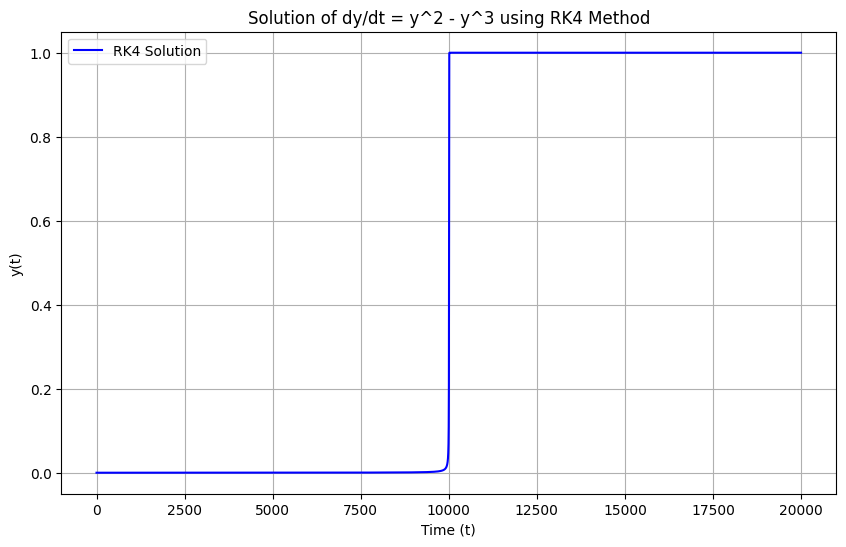

In [ ]:
# @title RK4 Solver dy/dt=y^2-y^3
initial_y = 0.0001 # @param {"type":"number","placeholder":"0.01"}
step_size = 1 # @param {"type":"number","placeholder":"1.0"}
import numpy as np
import matplotlib.pyplot as plt

# Define the ODE function dy/dt = f(y)
def f(y):
    return y**2 - y**3

# Classic Runge-Kutta 4th order method (RK4)
def rk4_solve(f, y0, t_span, h):
    t0, tf = t_span
    num_steps = int((tf - t0) / h)
    print('Number of steps:',num_steps)
    t_values = np.linspace(t0, tf, num_steps + 1)
    y_values = np.zeros(num_steps + 1)
    y_values[0] = y0

    for i in range(num_steps):
        t_n = t_values[i]
        y_n = y_values[i]

        k1 = h * f(y_n)
        k2 = h * f(y_n + k1/2)
        k3 = h * f(y_n + k2/2)
        k4 = h * f(y_n + k3)

        y_values[i+1] = y_n + (k1 + 2*k2 + 2*k3 + k4) / 6

    return t_values, y_values

# Initial conditions and parameters
y0 = initial_y  # Initial non-zero diameter, as mentioned in the notebook for stiffness
t_span = (0, 2./y0) # Time range to observe the full behavior
h = step_size    # Step size

# Solve the ODE using RK4
t, y = rk4_solve(f, y0, t_span, h)

# Plot the solution
plt.figure(figsize=(10, 6))
plt.plot(t, y, label='RK4 Solution', color='blue')
plt.xlabel('Time (t)')
plt.ylabel('y(t)')
plt.title('Solution of dy/dt = y^2 - y^3 using RK4 Method')
plt.grid(True)
plt.legend()
plt.show()

## 🔗 Bridge to Notebook 9.3

This notebook began by adding a temporal term to our previous model ODE, to illustrate how this results in a solution with multiple time-scale, and how the shorter time scale can restrict the step size as the longer time scale increase the require temporal evolution of the solution - driving the need for a large number of time-step.

Increasing the number of time-steps is not only an issue of computational cost, but may also lead to an accumulation of rounding-errors and stable, but less accurate solutions.

Theoretical examples, including a decaying exponential with multiple time constants and the flame propagation equation, are used to further demonstrate how you can derive stability conditions from perturbation analysis.

Take the time to understand this perturbation analysis process.

Notebook 9.3 will introduce Implicit Methods that can be used to enable more efficient solution of STIFF ODEs.

#🤖 AI Acknowledgment

MS CoPilot v25.6.440430001 was used proof read this notebook and suggested the flame propagation example when prompted for an stiff ODE example, and the python impementation of the RK4 algorithm, which was then modified by the author to include the form and input value fields to make it easier to experiment with the impact of the initial value and step size.